In [27]:
import pandas as pd
import numpy as np 
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
df = pd.read_csv("smartcart_customers.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


# Data Preprocessing

In [3]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [29]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = "median")
df["Income"] = imputer.fit_transform(df[["Income"]])

In [8]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engineering

In [60]:
# always drops ID from the 
data = df.copy()
data.drop("ID",axis=1,inplace=True)

In [61]:
# Year Birth as yearbirth is not useful so for numerical change this column into age 
data["Age"] = 2026 - data["Year_Birth"]

In [62]:
data.drop("Year_Birth",axis=1,inplace=True)

In [46]:
data.head()

,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Total_Children,Customer_days,Total_Spending
0,Graduated,Alone,58138.0,58,3,8,10,4,7,0,1,69,0,663,1617
1,Graduated,Alone,46344.0,38,2,1,1,2,5,0,0,72,2,113,27
2,Graduated,Together,71613.0,26,1,8,2,10,4,0,0,61,0,312,776
3,Graduated,Together,26646.0,26,2,2,0,4,6,0,0,42,1,139,53
4,PostGraduate,Together,58293.0,94,5,5,3,6,5,0,0,45,1,161,422


In [63]:
data["Education"].value_counts()
# convert it inot three categories undergraduate , graduate , postgraduate
categories = {
    "Graduation": "Graduated",
    "PhD": "PostGraduate",
    "Master": "PostGraduate",
    "2n Cycle": "UnderGraduate",
    "Basic": "UnderGraduate"
}
data["Education"] = data["Education"].map(categories)

In [64]:
data["Marital_Status"].value_counts()
# change them to two livingtype together or alone ..
categories={
    "Married":"Together",
    "Together":"Together",
    "Single":"Alone",
    "Divorced":"Alone",
    "Widow":"Alone",
    "Alone":"Alone",
    "Absurd":"Alone",
    "YOLO":"Alone",
}
data["Marital_Status"] = data["Marital_Status"].map(categories)
data["Marital_Status"].value_counts()

Marital_Status
Together    1444
Alone        796
Name: count, dtype: int64

In [65]:
data["Total_Children"] = data["Kidhome"]+data["Teenhome"]
data.drop(["Teenhome","Kidhome"],axis=1,inplace=True)

In [66]:
# Dt_Customer as datetime is not useable we convert it into days since from how many days has ecustomer joined 
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"],format = "%d-%m-%Y")
max_date = data["Dt_Customer"].max()
data["Customer_days"] = (max_date - data["Dt_Customer"]).dt.days
data.drop("Dt_Customer",axis=1,inplace=True)

In [75]:
data.columns

Index(['Education', 'Marital_Status', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age', 'Total_Children',
       'Customer_days', 'Total_Spending'],
      dtype='object')

In [67]:
data["Total_Spending"] = data["MntWines"] + data["MntFruits"] +data["MntMeatProducts"] +data["MntFishProducts"] +data["MntSweetProducts"] +data["MntGoldProds"]
data.drop(["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"],axis=1,inplace=True)

In [47]:
data.shape

(2240, 15)

# Outliers

In [68]:
data["Response"].value_counts()

Response
0    1906
1     334
Name: count, dtype: int64

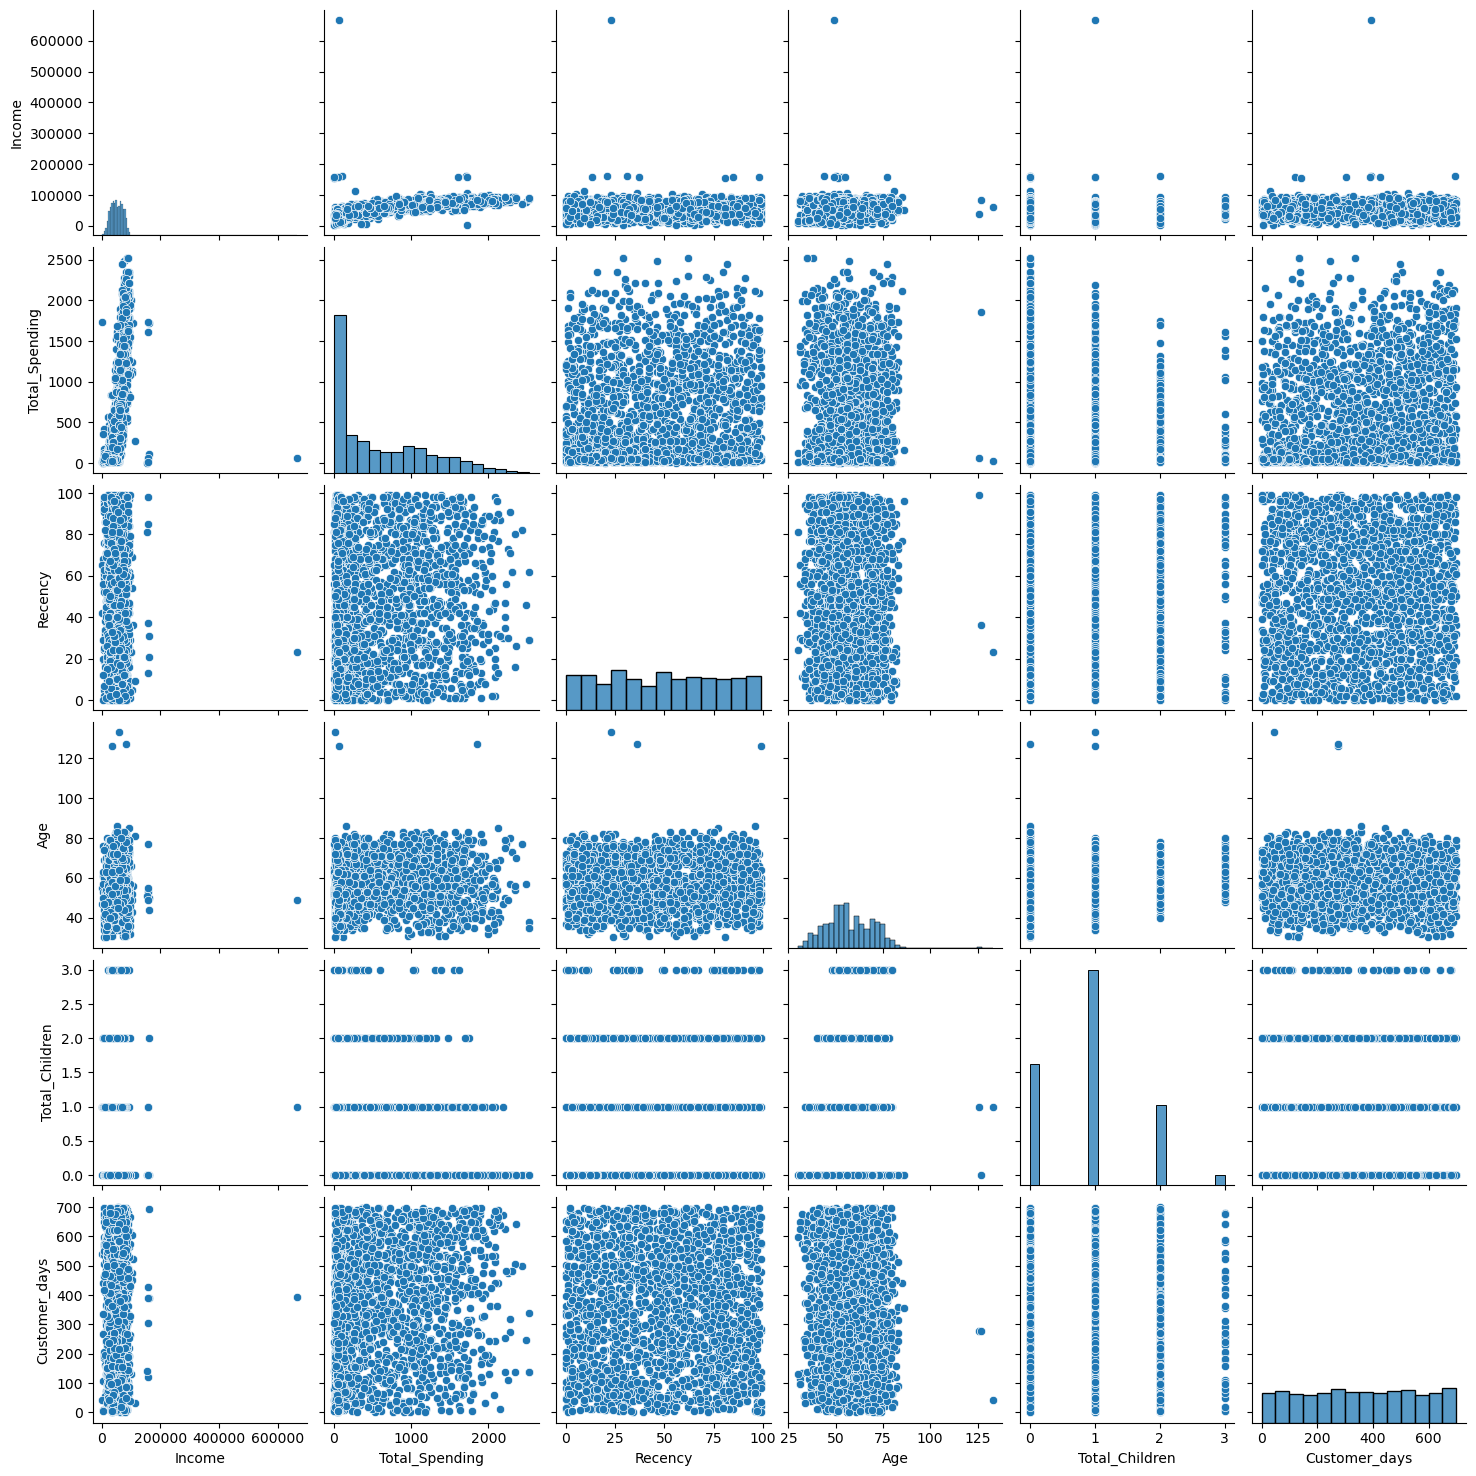

In [69]:
cols = ["Income","Total_Spending","Recency","Age","Total_Children","Customer_days"]
sns.pairplot(data[cols])
#Two outliers detected age > 100 && income >60000 

In [70]:
print(f"length before outliers = {len(data)}")
data = data[(data["Age"]<100)]
data = data[(data["Income"]<600000)]
print(f"length before outliers = {len(data)}")

length before outliers = 2240
length before outliers = 2236


# HeatMap
to check the corealtion of columns

In [71]:
corr = data.corr(numeric_only = True)

<Axes: >

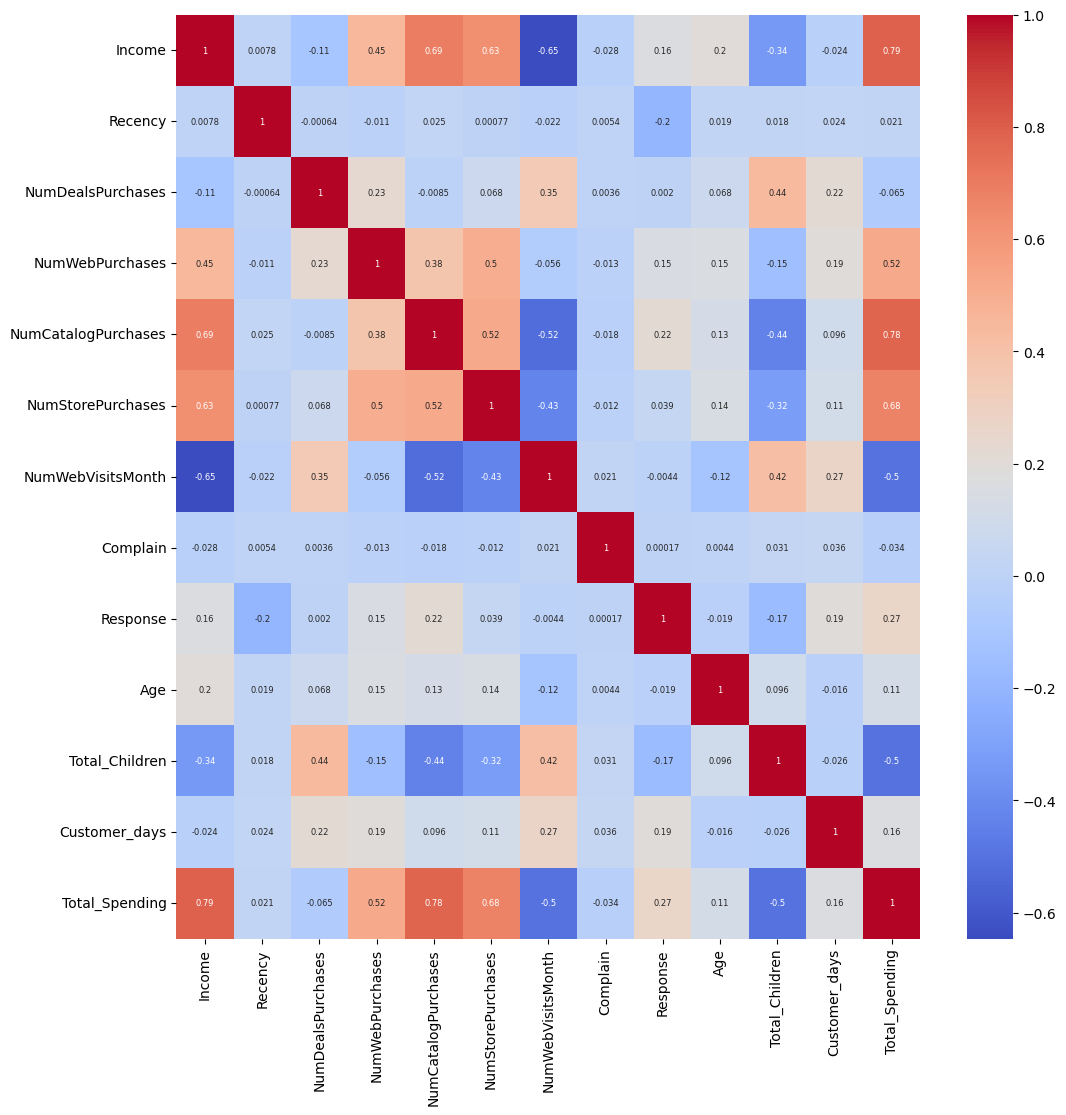

In [74]:
plt.figure(figsize=(12,12))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size": 6},
    cmap="coolwarm"
)

# Encoding

In [78]:
data.columns

Index(['Education', 'Marital_Status', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age', 'Total_Children',
       'Customer_days', 'Total_Spending'],
      dtype='object')

In [79]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
cols = ["Education","Marital_Status"]
ohe_enc = ohe.fit_transform(data[cols])

In [87]:
ohe_enc = pd.DataFrame(ohe_enc,columns=ohe.get_feature_names_out(cols),index=data.index)
data_encoded = pd.concat([data.drop(columns=cols),ohe_enc],axis=1)

In [88]:
data_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Total_Children,Customer_days,Total_Spending,Education_Graduated,Education_PostGraduate,Education_UnderGraduate,Marital_Status_Alone,Marital_Status_Together
0,58138.0,58,3,8,10,4,7,0,1,69,0,663,1617,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,2,113,27,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,0,312,776,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,1,139,53,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,1,161,422,0.0,1.0,0.0,0.0,1.0


# SCALING

In [89]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = data_encoded
X_scaled = scaler.fit_transform(X)

# CLUSTERING

In [96]:
# PCA perform PCS for decomposition of data
from sklearn.decomposition import PCA
pca = PCA(n_components = 3)
pca_data = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3D Visualization of PCA')

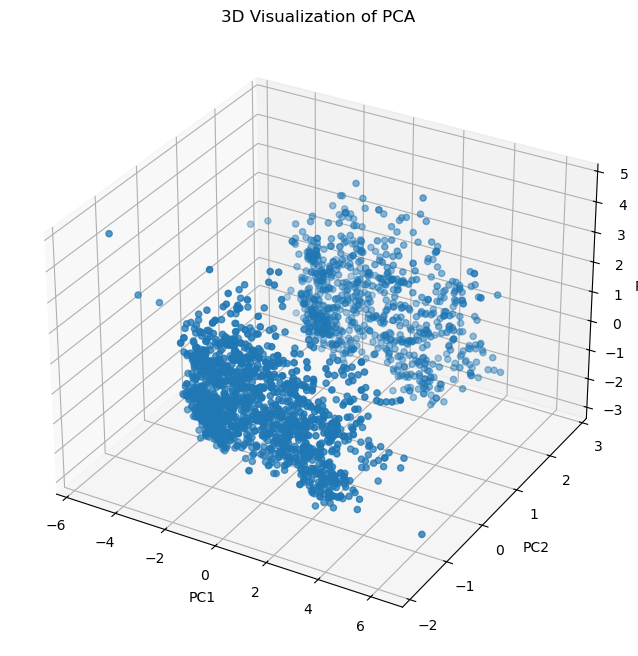

In [103]:
#Visualize pca
fig = plt.figure(figsize=(8,8))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(pca_data[:,0],pca_data[:,1],pca_data[:,2])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.title("3D Visualization of PCA")

In [107]:
# Kmeans using WCSS , Elbow method
from sklearn.cluster import KMeans
wcss = []
for k in range(2,11):
    kmean = KMeans(n_clusters = k , random_state = 42)
    kmean.fit_predict(pca_data)
    wcss.append(kmean.inertia_)
from kneed import KneeLocator
knee = KneeLocator(range(2,11),wcss,curve='convex',direction='decreasing')
print(f"Best K value is {knee.elbow}")
    

C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi

Best K value is 5


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


In [129]:
kmean = KMeans(n_clusters = 6 , random_state = 42)
labels = kmean.fit_predict(pca_data)


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


Text(0.5, 0.92, '3D Visualization ')

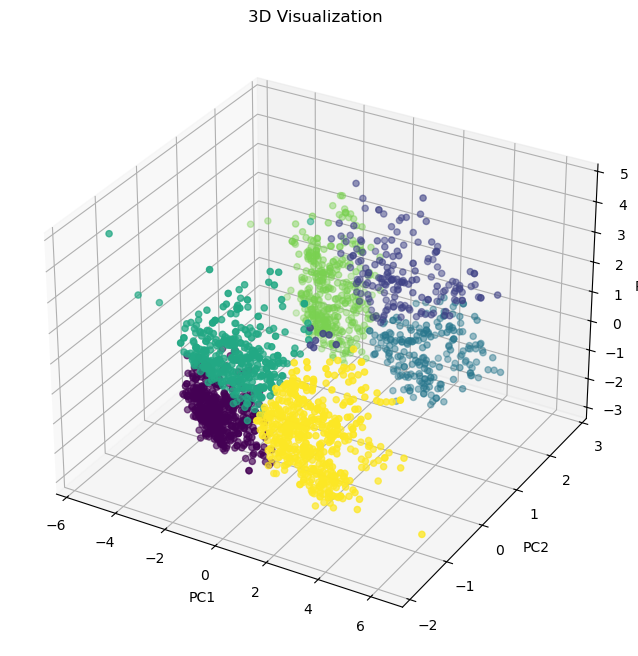

In [130]:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection= '3d')
ax.scatter(pca_data[:,0],pca_data[:,1],pca_data[:,2],c=labels)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.title("3D Visualization ")

# Characteristic of Cluster

In [132]:
X["Cluster"] = labels

In [120]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Total_Children,Customer_days,Total_Spending,Education_Graduated,Education_PostGraduate,Education_UnderGraduate,Marital_Status_Alone,Marital_Status_Together,Cluster
0,58138.0,58,3,8,10,4,7,0,1,69,0,663,1617,1.0,0.0,0.0,1.0,0.0,2
1,46344.0,38,2,1,1,2,5,0,0,72,2,113,27,1.0,0.0,0.0,1.0,0.0,4
2,71613.0,26,1,8,2,10,4,0,0,61,0,312,776,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,1,139,53,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,1,161,422,0.0,1.0,0.0,0.0,1.0,3


<Axes: xlabel='Cluster', ylabel='count'>

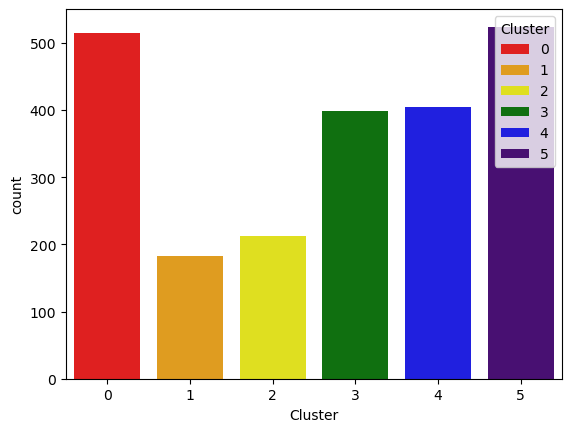

In [133]:
pal = ["red","orange","yellow","green","blue","indigo"]
sns.countplot(x=X["Cluster"],palette=pal,hue=X["Cluster"])

<Axes: xlabel='Income', ylabel='Total_Spending'>

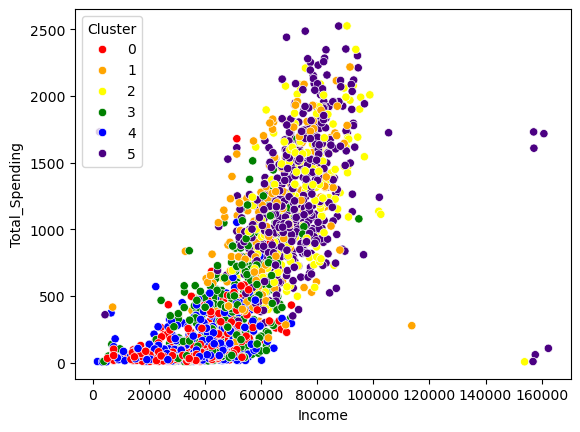

In [134]:
sns.scatterplot(x=X["Income"],y=X["Total_Spending"],hue = X["Cluster"],palette=pal)

In [137]:
cluster_summary = X.groupby("Cluster").mean()
cluster_summary

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Total_Children,Customer_days,Total_Spending,Education_Graduated,Education_PostGraduate,Education_UnderGraduate,Marital_Status_Alone,Marital_Status_Together
Cluster,,,,,,,,,,,,,,,,,,
0,34116.545720,51.124514,2.009728,2.297665,0.577821,3.433852,6.422179,0.015564,0.048638,52.994163,1.163424,335.167315,123.011673,0.715953,0.066148,0.217899,0.000000,1.000000
1,62861.767760,47.393443,3.071038,6.595628,4.010929,8.103825,5.234973,0.000000,0.377049,62.710383,0.775956,450.229508,1021.131148,0.120219,0.830601,0.049180,0.961749,0.038251
2,74183.842723,52.225352,1.370892,5.084507,5.417840,8.295775,2.985915,0.009390,0.286385,56.497653,0.347418,327.981221,1224.075117,0.802817,0.126761,0.070423,1.000000,0.000000
3,46844.678392,47.344221,3.537688,4.266332,1.595477,5.180905,6.457286,0.000000,0.125628,60.143216,1.396985,368.753769,366.854271,0.092965,0.856784,0.050251,0.002513,0.997487
4,35878.794554,48.356436,2.358911,2.492574,0.712871,3.396040,6.569307,0.012376,0.131188,54.804455,1.262376,332.391089,134.626238,0.532178,0.321782,0.146040,1.000000,0.000000
5,72874.166985,48.416031,1.818702,5.656489,5.433206,8.606870,3.385496,0.009542,0.145038,58.879771,0.469466,353.929389,1228.561069,0.597328,0.326336,0.076336,0.000000,1.000000
